# Solar Power Prediction

## Step 0 – Imports and settings

In [75]:
import time
import json
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import requests
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [76]:
DATA_FILE  = Path("solar_weather_dataset.csv")
MODEL_FILE = Path("models/solar_model.joblib")
CACHE_FILE = Path("last_forecast.csv")      # saved copy of the last good API response
Path("models").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

TARGET = "solar_output"

## Step 1 – Generate the dataset

In [77]:
np.random.seed(42)
rows = []
start = datetime(2024, 1, 1)

for i in range(24 * 60):
    ts = start + timedelta(hours=i)
    hour = ts.hour

    temperature   = 18 + 10 * np.sin((hour / 24) * 2 * np.pi) + np.random.normal(0, 1)
    humidity      = np.clip(60 + np.random.normal(0, 10), 20, 100)
    cloud_cover   = np.clip(np.random.normal(40, 25), 0, 100)
    wind_speed    = np.clip(np.random.normal(5, 2), 0, 15)
    precipitation = max(0, np.random.normal(0.2, 0.5))

    daylight_factor = max(0, np.sin((hour - 6) / 12 * np.pi))
    solar_output = max(0, daylight_factor * (1 - cloud_cover / 120) * (temperature / 30) * 1000)
    solar_output = max(0, solar_output + np.random.normal(0, 20))

    rows.append([ts.strftime("%Y-%m-%d %H:%M:%S"), temperature, humidity,
                 cloud_cover, wind_speed, precipitation, solar_output])

raw = pd.DataFrame(rows, columns=["timestamp", "temperature", "humidity", "cloud_cover",
                                  "wind_speed", "precipitation", "solar_output"])
raw.to_csv(DATA_FILE, index=False)
print("Dataset created:", DATA_FILE, raw.shape)

Dataset created: solar_weather_dataset.csv (1440, 7)


## Step 2 – Load and clean the data

In [78]:
df = pd.read_csv(DATA_FILE, parse_dates=["timestamp"])
df.head()

,timestamp,temperature,humidity,cloud_cover,wind_speed,precipitation,solar_output
0,2024-01-01 00:00:00,18.496714,58.617357,56.192213,8.046060,0.082923,0.000000
1,2024-01-01 01:00:00,22.167403,67.674347,28.263140,6.085120,0.000000,0.000000
2,2024-01-01 02:00:00,23.241962,40.867198,0.000000,3.875425,0.000000,6.284947
3,2024-01-01 03:00:00,24.163044,45.876963,76.641219,4.548447,0.233764,0.000000
4,2024-01-01 04:00:00,26.115871,61.109226,11.225161,5.751396,0.000000,0.000000


In [79]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate timestamps:", df["timestamp"].duplicated().sum())

expected_hours = pd.date_range(df["timestamp"].min(), df["timestamp"].max(), freq="h")
print("Missing hourly rows:", len(expected_hours) - len(df))

Missing values per column:
timestamp        0
temperature      0
humidity         0
cloud_cover      0
wind_speed       0
precipitation    0
solar_output     0
dtype: int64

Duplicate timestamps: 0
Missing hourly rows: 0


In [80]:
df = df.sort_values("timestamp").drop_duplicates("timestamp").set_index("timestamp")
df = df.reindex(expected_hours)                 # complete hourly timeline
df.index.name = "timestamp"

df = df.interpolate(method="linear", limit_direction="both")   # fill gaps

df["humidity"]      = df["humidity"].clip(0, 100)
df["cloud_cover"]   = df["cloud_cover"].clip(0, 100)
df["wind_speed"]    = df["wind_speed"].clip(lower=0)
df["precipitation"] = df["precipitation"].clip(lower=0)
df[TARGET]          = df[TARGET].clip(lower=0)

df = df.reset_index()
print("Missing values left:", df.isna().sum().sum())

Missing values left: 0


## Step 3 – Quick look at the data

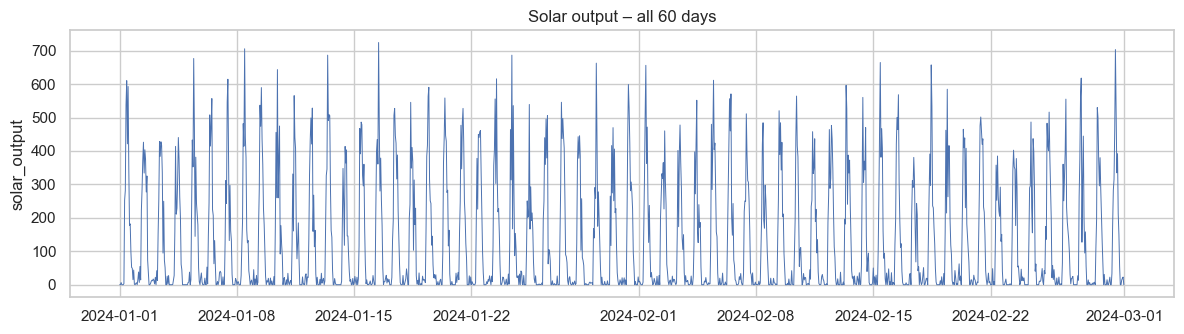

In [81]:
plt.figure(figsize=(12, 3.5))
plt.plot(df["timestamp"], df[TARGET], linewidth=0.7)
plt.title("Solar output – all 60 days")
plt.ylabel("solar_output")
plt.tight_layout()
plt.show()

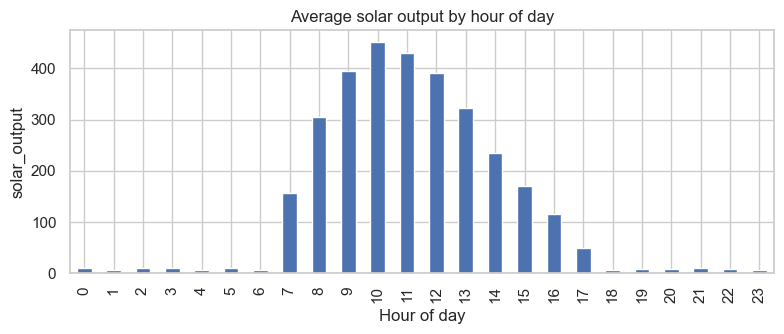

In [82]:
hourly_avg = df.groupby(df["timestamp"].dt.hour)[TARGET].mean()

plt.figure(figsize=(8, 3.5))
hourly_avg.plot(kind="bar")
plt.title("Average solar output by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("solar_output")
plt.tight_layout()
plt.show()

## Step 4 – Feature engineering

In [83]:
FEATURES = ["temperature", "humidity", "cloud_cover", "wind_speed", "precipitation",
            "hour", "hour_sin", "hour_cos", "day_of_week", "is_weekend"]

def add_time_features(data):
    out = data.copy()
    out["hour"]        = out["timestamp"].dt.hour
    out["hour_sin"]    = np.sin(2 * np.pi * out["hour"] / 24)
    out["hour_cos"]    = np.cos(2 * np.pi * out["hour"] / 24)
    out["day_of_week"] = out["timestamp"].dt.dayofweek
    out["is_weekend"]  = (out["day_of_week"] >= 5).astype(int)
    return out

In [84]:
df = add_time_features(df)
df[["timestamp", "hour", "hour_sin", "hour_cos", "day_of_week", "is_weekend"]].head()

,timestamp,hour,hour_sin,hour_cos,day_of_week,is_weekend
0,2024-01-01 00:00:00,0,0.000000,1.000000,0,0
1,2024-01-01 01:00:00,1,0.258819,0.965926,0,0
2,2024-01-01 02:00:00,2,0.500000,0.866025,0,0
3,2024-01-01 03:00:00,3,0.707107,0.707107,0,0
4,2024-01-01 04:00:00,4,0.866025,0.500000,0,0


## Step 5 – Chronological split: 50 days train, 10 days validation


In [85]:
TRAIN_ROWS = 50 * 24          # 1200 rows = 50 days

train = df.iloc[:TRAIN_ROWS]
valid = df.iloc[TRAIN_ROWS:]

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]

In [86]:
print(f"Train      : {len(train)} rows  ({len(train) // 24} days)  {train['timestamp'].min()}  ->  {train['timestamp'].max()}")
print(f"Validation : {len(valid)} rows  ({len(valid) // 24} days)  {valid['timestamp'].min()}  ->  {valid['timestamp'].max()}")

Train      : 1200 rows  (50 days)  2024-01-01 00:00:00  ->  2024-02-19 23:00:00
Validation : 240 rows  (10 days)  2024-02-20 00:00:00  ->  2024-02-29 23:00:00


## Step 6 – Train and tune three models
**Random Forest, XGBoost and LightGBM**.

In [87]:
models = {
    "Random Forest": (RandomForestRegressor(random_state=42),
                      {"n_estimators": [100, 200], "max_depth": [8, 15]}),

    "XGBoost":       (XGBRegressor(random_state=42, verbosity=0),
                      {"n_estimators": [100, 200], "max_depth": [3, 5]}),

    "LightGBM":      (LGBMRegressor(random_state=42, verbose=-1),
                      {"n_estimators": [100, 200], "num_leaves": [15, 31]}),
}

In [88]:
tscv = TimeSeriesSplit(n_splits=3)
tuned = {}

for name, (model, grid) in models.items():
    search = GridSearchCV(model, grid, cv=tscv, scoring="neg_root_mean_squared_error")
    search.fit(X_train, y_train)
    tuned[name] = search
    print(f"{name:14s} best CV RMSE = {-search.best_score_:.2f}   params = {search.best_params_}")

Random Forest  best CV RMSE = 25.79   params = {'max_depth': 8, 'n_estimators': 200}
XGBoost        best CV RMSE = 23.02   params = {'max_depth': 3, 'n_estimators': 100}
LightGBM       best CV RMSE = 22.74   params = {'n_estimators': 200, 'num_leaves': 15}


In [89]:
best_name  = min(tuned, key=lambda n: -tuned[n].best_score_)
best_model = tuned[best_name].best_estimator_
print("Selected model:", best_name)

Selected model: LightGBM


## Step 7 – Evaluate on the 10 validation days
- **MAE** – average error (same unit as solar_output)
- **RMSE** – like MAE but punishes big errors more
- **R²** – 1.0 is perfect; 0 means no better than guessing the average

Predictions are clipped at 0 because solar output can't be negative.

In [90]:
def evaluate(model):
    pred = np.clip(model.predict(X_valid), 0, None)
    return {"MAE":  mean_absolute_error(y_valid, pred),
            "RMSE": np.sqrt(mean_squared_error(y_valid, pred)),
            "R2":   r2_score(y_valid, pred)}

results = pd.DataFrame({name: evaluate(s.best_estimator_) for name, s in tuned.items()}).T
results["CV RMSE (train)"] = [-tuned[n].best_score_ for n in results.index]
results.round(3)

,MAE,RMSE,R2,CV RMSE (train)
Random Forest,15.067,20.721,0.985,25.794
XGBoost,15.360,20.979,0.984,23.016
LightGBM,15.315,20.256,0.985,22.739


In [91]:
valid_pred = np.clip(best_model.predict(X_valid), 0, None)
metrics = evaluate(best_model)

print(f"Selected model: {best_name}")
print(f"MAE  = {metrics['MAE']:.2f}")
print(f"RMSE = {metrics['RMSE']:.2f}")
print(f"R²   = {metrics['R2']:.4f}")

Selected model: LightGBM
MAE  = 15.32
RMSE = 20.26
R²   = 0.9852


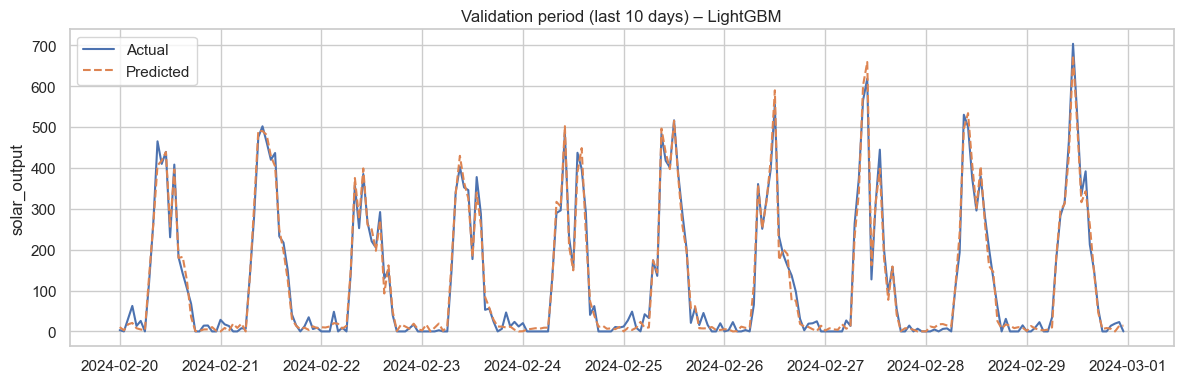

In [92]:
plt.figure(figsize=(12, 4))
plt.plot(valid["timestamp"], y_valid, label="Actual")
plt.plot(valid["timestamp"], valid_pred, label="Predicted", linestyle="--")
plt.title(f"Validation period (last 10 days) – {best_name}")
plt.ylabel("solar_output")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/validation_actual_vs_predicted.png", dpi=150)
plt.show()

## Step 8 – Save the model

In [93]:
bundle = {
    "model":       best_model,
    "model_name":  best_name,
    "features":    FEATURES,
    "fill_values": X_train.median().to_dict(),
}
joblib.dump(bundle, MODEL_FILE)

Path("outputs/model_metrics.json").write_text(json.dumps(
    {"model": best_name, **{k: round(float(v), 4) for k, v in metrics.items()}}, indent=2))
print("Saved:", MODEL_FILE)

Saved: models\solar_model.joblib


## Step 9 – Get the weather forecast
*temperature, humidity, cloud cover, wind speed (in m/s) and precipitation.*

In [94]:
API_URL   = "https://api.open-meteo.com/v1/forecast"
LAT, LON  = 18.52, 73.86            # Pune
HOURS     = 48

# API field name  ->  our column name
API_TO_FEATURE = {
    "temperature_2m":       "temperature",
    "relative_humidity_2m": "humidity",
    "cloud_cover":          "cloud_cover",
    "wind_speed_10m":       "wind_speed",
    "precipitation":        "precipitation",
}

In [95]:
def fetch_forecast(retries=3):
    params = {"latitude": LAT, "longitude": LON,
              "hourly": ",".join(API_TO_FEATURE),
              "forecast_days": 3,
              "timezone": "Asia/Kolkata",
              "wind_speed_unit": "ms"}

    for attempt in range(retries):
        try:
            response = requests.get(API_URL, params=params, timeout=20)
            if response.status_code == 429:               # rate limit -> wait, retry
                time.sleep(5 * 2 ** attempt)
                continue
            response.raise_for_status()
            return response.json()["hourly"]
        except (requests.RequestException, KeyError, ValueError) as error:
            print(f"Attempt {attempt + 1} failed: {error}")
            time.sleep(2 ** attempt)
    return None

In [96]:
def build_forecast_df(hourly):
    out = pd.DataFrame({"timestamp": pd.to_datetime(hourly["time"])})

    for api_name, column in API_TO_FEATURE.items():
        values = hourly.get(api_name)
        out[column] = pd.to_numeric(pd.Series(values), errors="coerce") if values else np.nan

    out = out.interpolate(limit_direction="both")              # fill small gaps
    for column, value in bundle["fill_values"].items():        # fill fully-missing fields
        if column in out:
            out[column] = out[column].fillna(value)

    out["humidity"]    = out["humidity"].clip(0, 100)
    out["cloud_cover"] = out["cloud_cover"].clip(0, 100)

    now = pd.Timestamp.now(tz="Asia/Kolkata").floor("h").tz_localize(None)
    return out[out["timestamp"] >= now].head(HOURS).reset_index(drop=True)

In [97]:
hourly = fetch_forecast()

if hourly is not None:
    forecast_weather = build_forecast_df(hourly)
    forecast_weather.to_csv(CACHE_FILE, index=False)           # cache for next time
    print("Live forecast fetched:", forecast_weather.shape)
elif CACHE_FILE.exists():
    print("API unavailable -> using the last saved forecast")
    forecast_weather = pd.read_csv(CACHE_FILE, parse_dates=["timestamp"])
else:
    raise RuntimeError("API unavailable and no saved forecast. Check your internet and rerun.")

forecast_weather.head()

Live forecast fetched: (48, 6)


,timestamp,temperature,humidity,cloud_cover,wind_speed,precipitation
0,2026-11-19 16:00:00,27.7,28,0,2.76,0.0
1,2026-11-19 17:00:00,26.9,30,0,2.67,0.0
2,2026-11-19 18:00:00,25.6,33,0,2.44,0.0
3,2026-11-19 19:00:00,24.5,35,0,2.66,0.0
4,2026-11-19 20:00:00,23.7,37,0,2.36,0.0


## Step 10 – Predict future solar output

In [98]:
saved = joblib.load(MODEL_FILE)

forecast_X = add_time_features(forecast_weather)[saved["features"]]
predictions = np.clip(saved["model"].predict(forecast_X), 0, None)

forecast = forecast_weather[["timestamp"]].copy()
forecast["predicted_solar_output"] = predictions.round(2)
forecast.to_csv("outputs/solar_predictions.csv", index=False)
forecast.head()

,timestamp,predicted_solar_output
0,2026-11-19 16:00:00,521.73
1,2026-11-19 17:00:00,226.94
2,2026-11-19 18:00:00,21.44
3,2026-11-19 19:00:00,19.39
4,2026-11-19 20:00:00,11.60


## Step 11 – Plot history + forecast

In [99]:
history = df[["timestamp", TARGET]].tail(7 * 24).copy()          # last 7 days
forecast_start = forecast["timestamp"].min()

history["plot_time"] = pd.date_range(end=forecast_start - pd.Timedelta(hours=1),
                                     periods=len(history), freq="h")

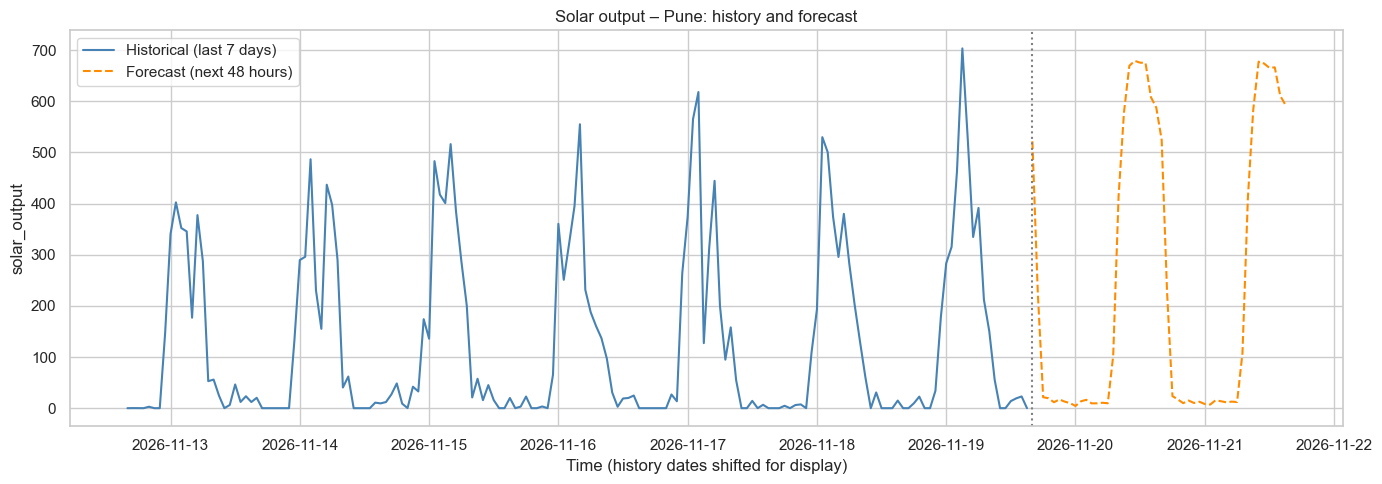

In [100]:
plt.figure(figsize=(14, 5))
plt.plot(history["plot_time"], history[TARGET], label="Historical (last 7 days)", color="steelblue")
plt.plot(forecast["timestamp"], forecast["predicted_solar_output"],
         label="Forecast (next 48 hours)", color="darkorange", linestyle="--")
plt.axvline(forecast_start, color="gray", linestyle=":")
plt.title("Solar output – Pune: history and forecast")
plt.xlabel("Time (history dates shifted for display)")
plt.ylabel("solar_output")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/solar_forecast_chart.png", dpi=150)
plt.show()

In [101]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=history["plot_time"], y=history[TARGET],
                         name="Historical", line=dict(color="steelblue")))
fig.add_trace(go.Scatter(x=forecast["timestamp"], y=forecast["predicted_solar_output"],
                         name="Forecast", line=dict(color="darkorange", dash="dash")))
fig.add_shape(type="line", x0=forecast_start, x1=forecast_start, y0=0, y1=1,
              yref="paper", line=dict(color="gray", dash="dot"))
fig.update_layout(title="Solar output – Pune: history and forecast",
                  xaxis_title="Time (history dates shifted for display)",
                  yaxis_title="solar_output", height=450)
fig.write_html("outputs/solar_forecast_interactive.html")
fig.show()

## Step 12 – Table of the next 24 hours

In [102]:
next_24h = forecast.head(24).copy()
next_24h["timestamp"] = next_24h["timestamp"].dt.strftime("%Y-%m-%d %H:%M")
next_24h.to_csv("outputs/sample_24h_predictions.csv", index=False)
next_24h

,timestamp,predicted_solar_output
0,2026-11-19 16:00,521.73
1,2026-11-19 17:00,226.94
2,2026-11-19 18:00,21.44
3,2026-11-19 19:00,19.39
4,2026-11-19 20:00,11.60
5,2026-11-19 21:00,17.01
6,2026-11-19 22:00,12.82
7,2026-11-19 23:00,9.87
8,2026-11-20 00:00,4.39
9,2026-11-20 01:00,13.36
